# 07 · Del EVER temprano a la pérdida, y de la cosecha al ciclo

**Preguntas de decisión**

1. **¿El EVER30@MOB3 predice la pérdida o solo es rápido?** Un indicador temprano sirve para gobernar la originación si se puede traducir a castigo y a pesos. Sin ese puente, un segmento puede verse peor a MOB 3 solo porque cae y se cura antes.
2. **¿Qué cosecha salió mala y qué fue culpa del ciclo?** Una cohorte por encima de lo esperado puede reflejar la calidad de originación, que el equipo controla, o el entorno del mes en que maduró, que no controla. Las acciones son distintas.

**Impacto esperado:** leer una cosecha de 3 meses como si tuviera 18, en pérdida esperada en COP, y llevar al comité una separación entre originación y entorno.

> **Estado:** plantilla. Con los archivos del repositorio, que solo tienen encabezados, las secciones *Con datos de la entidad* quedan en PENDIENTE. Las secciones *Demostración aislada* usan una cartera **simulada** con mecanismos plantados y verifican con `assert` que los métodos recuperan esa verdad. No son resultados de una cartera.

## Encaje en el flujo

| Entrada | Viene de | Se usa para |
|---|---|---|
| EVER30@MOB3 por cuenta | notebook 02 (`build_vintage`) | evento temprano $E_i$ |
| Castigo y pérdida a MOB 18 | `plantilla_desempeno_largo.csv` (nueva) | resultado largo $C_i$ |
| Serie macro mensual | `plantilla_macro_mensual.csv` (nueva) | efecto período |
| Política vigente por cohorte | `plantilla_politicas.csv` | lectura de efectos de cohorte |

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'decision_core.py').exists():
    root = next(p for p in [BASE, *BASE.parents] if (p / '03-financial-risk').is_dir())
    BASE = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(BASE))
import decision_core as dc
from vintage_core import build_vintage, summarize_vintage
from demo_inputs import demo_cartera
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
AZUL, OCRE, GRIS, ROJO = '#25658c', '#d4854a', '#9aa5b1', '#b5443b'
SIM = 'Datos simulados · no representa una cartera'
pd.options.display.float_format = '{:,.4f}'.format

def leer(nombre):
    """Lee una plantilla local; las del repositorio solo tienen encabezados."""
    return pd.read_csv(BASE / nombre, encoding='utf-8-sig')

def pct(x, d=1):
    return 'n/d' if pd.isna(x) else f'{100 * x:.{d}f} %'

def cop(x):
    return 'n/d' if pd.isna(x) else f'COP {x / 1e6:,.1f} M'

## 1 · Puente entre la mora temprana y el castigo

Entre las cuentas con seguimiento largo completo (cosechas maduras):

$$a=\Pr(C=1\mid E=1),\qquad b=\Pr(C=1\mid E=0),\qquad \text{lift}=a/b,\qquad \text{captura}=\Pr(E=1\mid C=1).$$

La **captura** dice qué parte de los castigos anunció el indicador temprano; la parte restante llega por un deterioro posterior a MOB 3 que el backtest de onboarding no ve. Para una cosecha joven con tasa temprana $r$:

$$\widehat{L}=r\,a+(1-r)\,b,$$

y la pérdida esperada en pesos es $\widehat{L}\times$ saldo $\times$ severidad, con severidad = pérdida neta / saldo entre castigados. **Supuesto crítico:** $a$ y $b$ son estables entre cosechas y segmentos. Se verifica por cohorte madura antes de proyectar, y se re-estima cuando cambian la política, el producto o la cobranza.

### Con datos de la entidad

In [2]:
largo = leer('plantilla_desempeno_largo.csv')
panel = leer('plantilla_panel_mensual.csv')
print(f'Filas de desempeño largo: {len(largo):,} | filas de panel: {len(panel):,}')
if largo.empty or panel.empty:
    print('PENDIENTE: cargar castigos y pérdida neta a MOB 18 con fecha de disponibilidad, y el panel mensual.')
else:
    accounts, _ = build_vintage(panel)
    base = accounts.loc[accounts.es_evaluable].assign(evento_temprano=lambda d: d.evento_mora_mayor_30.astype(int))
    base = base.merge(largo, on=['id_credito', 'id_comercio', 'corte_origen'], how='left', validate='one_to_one')
    base['seguimiento_largo_completo'] = base.seguimiento_largo_completo.fillna(0)
    base = base.rename(columns={'saldo': 'saldo_mob3'})
    display(dc.bridge_to_loss(base))

Filas de desempeño largo: 0 | filas de panel: 0
PENDIENTE: cargar castigos y pérdida neta a MOB 18 con fecha de disponibilidad, y el panel mensual.


### Demostración aislada: puente por tipo de persona

In [3]:
# Cartera ficticia con mecanismos plantados (ver demo_inputs.demo_cartera).
DEMO = demo_cartera()
V = DEMO['verdad']
cuentas, solicitudes, panel_demo, macro_demo = DEMO['cuentas'], DEMO['solicitudes'], DEMO['panel'], DEMO['macro']
cuentas['banda_score'] = pd.cut(cuentas.score_buro, [0, 620, 660, 700, 2000], right=False,
                                labels=['<620', '620–659', '660–699', '700+'])
print(f'Solicitudes simuladas: {len(solicitudes):,} | aprobadas: {len(cuentas):,} | '
      f'EVER30@MOB3 simulado: {pct(cuentas.evento_temprano.mean())}')

Solicitudes simuladas: 30,000 | aprobadas: 20,379 | EVER30@MOB3 simulado: 10.5 %


Cosechas con seguimiento a MOB 18 al corte 2025-09 : 2024-01, 2024-02, 2024-03


,tipo_persona,n,n_evento,p_castigo_dado_evento,ic_bajo,ic_alto,p_castigo_sin_evento,lift,captura,tasa_perdida_saldo
0,juridica,1518,145,0.3103,0.2408,0.3897,0.0131,23.6724,0.7143,0.0318
1,natural,3511,405,0.3975,0.3510,0.4459,0.0216,18.4288,0.7061,0.0535


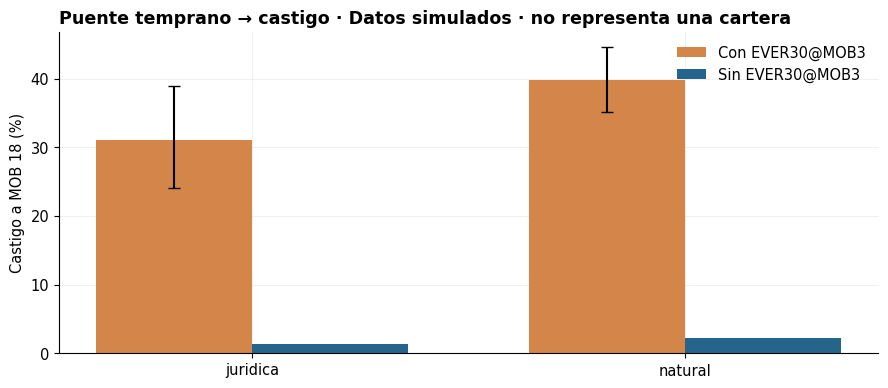

,tipo_persona,p_castigo_dado_evento,ic_bajo,ic_alto,plantado
0,juridica,0.3103,0.2408,0.3897,0.3500
1,natural,0.3975,0.3510,0.4459,0.4500


Prueba: el IC 99 % de P(castigo | evento) contiene el valor plantado en ambos tipos de persona.


In [4]:
puente = dc.bridge_to_loss(cuentas, segment_cols=['tipo_persona'])
maduras = cuentas.loc[cuentas.seguimiento_largo_completo == 1, 'corte_origen'].unique()
print('Cosechas con seguimiento a MOB 18 al corte', V['fecha_asof'], ':', ', '.join(sorted(maduras)))
display(puente[['tipo_persona', 'n', 'n_evento', 'p_castigo_dado_evento', 'ic_bajo', 'ic_alto',
                'p_castigo_sin_evento', 'lift', 'captura', 'tasa_perdida_saldo']])

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(puente))
ax.bar(x - .18, 100 * puente.p_castigo_dado_evento, .36, color=OCRE, label='Con EVER30@MOB3',
       yerr=[100 * (puente.p_castigo_dado_evento - puente.ic_bajo), 100 * (puente.ic_alto - puente.p_castigo_dado_evento)], capsize=4)
ax.bar(x + .18, 100 * puente.p_castigo_sin_evento, .36, color=AZUL, label='Sin EVER30@MOB3')
ax.set_xticks(x, puente.tipo_persona)
ax.set(ylabel='Castigo a MOB 18 (%)', title=f'Puente temprano → castigo · {SIM}')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

control = puente[['tipo_persona', 'p_castigo_dado_evento', 'ic_bajo', 'ic_alto']].assign(
    plantado=puente.tipo_persona.map(V['p_castigo_dado_evento']))
display(control)
# Una sola realización: se verifica con tolerancia del 99 % (con IC 95 %, 1 de cada 20 semillas fallaría por azar).
for _, r in puente.iterrows():
    lo99, hi99 = dc.wilson_interval(round(r.p_castigo_dado_evento * r.n_evento), r.n_evento, z=2.576)
    assert lo99 <= V['p_castigo_dado_evento'][r.tipo_persona] <= hi99, 'El puente no recupera la verdad plantada'
print('Prueba: el IC 99 % de P(castigo | evento) contiene el valor plantado en ambos tipos de persona.')

**Estabilidad del puente.** Si $a$ cambia mucho entre las cosechas maduras, la proyección de cosechas jóvenes no es confiable; en ese caso se reporta un rango, no un punto.

In [5]:
estab = dc.bridge_to_loss(cuentas, segment_cols=['corte_origen'])
display(estab[['corte_origen', 'n', 'n_evento', 'p_castigo_dado_evento', 'ic_bajo', 'ic_alto', 'p_castigo_sin_evento']])
rango = estab.p_castigo_dado_evento.max() - estab.p_castigo_dado_evento.min()
solapan = estab.ic_bajo.max() <= estab.ic_alto.min()
print(f'Rango de P(castigo | evento) entre cosechas maduras: {pct(rango)} | los IC se solapan: {solapan}')

,corte_origen,n,n_evento,p_castigo_dado_evento,ic_bajo,ic_alto,p_castigo_sin_evento
0,2024-01,1686,203,0.4138,0.3483,0.4825,0.0148
1,2024-02,1664,188,0.3883,0.3215,0.4595,0.0149
2,2024-03,1679,159,0.3082,0.2416,0.3838,0.0270


Rango de P(castigo | evento) entre cosechas maduras: 10.6 % | los IC se solapan: True


**Traducción de cosechas jóvenes a pérdida esperada.** Se aplica el puente por tipo de persona a la tasa temprana de cada cohorte sin seguimiento largo.

In [6]:
p = puente.set_index('tipo_persona')
castigados = cuentas[(cuentas.seguimiento_largo_completo == 1) & (cuentas.castigo_largo == 1)]
severidad = castigados.perdida_neta_cop.sum() / castigados.saldo_mob3.sum()
jovenes = cuentas[cuentas.seguimiento_largo_completo == 0]
g = jovenes.groupby(['corte_origen', 'tipo_persona']).agg(n=('evento_temprano', 'size'), tasa=('evento_temprano', 'mean'),
                                                          saldo=('saldo_mob3', 'sum')).reset_index()
g['castigo_proyectado'] = [dc.implied_loss_rate(r.tasa, p.loc[r.tipo_persona, 'p_castigo_dado_evento'],
                                                p.loc[r.tipo_persona, 'p_castigo_sin_evento']) for r in g.itertuples()]
g['perdida_esperada_cop'] = g.castigo_proyectado * g.saldo * severidad
proy = g.groupby('corte_origen').agg(n=('n', 'sum'), perdida_esperada_cop=('perdida_esperada_cop', 'sum'), saldo=('saldo', 'sum'))
proy['tasa_perdida_proyectada'] = proy.perdida_esperada_cop / proy.saldo
display(proy.assign(perdida_esperada_mm=lambda d: (d.perdida_esperada_cop / 1e6).round(1), saldo_mm=lambda d: (d.saldo / 1e6).round(0))
            [['n', 'saldo_mm', 'perdida_esperada_mm', 'tasa_perdida_proyectada']])
peor = proy.tasa_perdida_proyectada.idxmax()
display(Markdown(f"**Lectura (simulada).** Con severidad {pct(severidad)}, la cohorte **{peor}** proyecta la mayor pérdida: "
                 f"{pct(proy.loc[peor, 'tasa_perdida_proyectada'], 2)} del saldo, unos {cop(proy.loc[peor, 'perdida_esperada_cop'])}. "
                 f"El puente explica {pct(puente.captura.mean(), 0)} de los castigos; el resto aparece después de MOB 3 y "
                 "requiere seguimiento de comportamiento, no solo de originación."))

,n,saldo_mm,perdida_esperada_mm,tasa_perdida_proyectada
corte_origen,,,,
2024-04,1764,"2,197.0000",102.6000,0.0467
2024-05,1691,"2,059.0000",87.2000,0.0423
2024-06,1693,"2,085.0000",101.0000,0.0484
2024-07,1698,"2,068.0000",88.9000,0.0430
2024-08,1733,"2,092.0000",90.7000,0.0434
2024-09,1629,"1,971.0000",122.9000,0.0623
2024-10,1760,"2,172.0000",102.3000,0.0471
2024-11,1661,"2,007.0000",86.7000,0.0432
2024-12,1721,"2,087.0000",106.2000,0.0509


**Lectura (simulada).** Con severidad 84.7 %, la cohorte **2024-09** proyecta la mayor pérdida: 6.23 % del saldo, unos COP 122.9 M. El puente explica 71 % de los castigos; el resto aparece después de MOB 3 y requiere seguimiento de comportamiento, no solo de originación.

## 2 · Curva esperada, bandas de control y efecto de cohorte

**Bandas.** Con cohortes de referencia se fija la tasa esperada por MOB, $\bar p_m$. Para una cohorte con $n$ cuentas, la banda es $\bar p_m \pm z\sqrt{\varphi\,\bar p_m(1-\bar p_m)/n}$, donde $\varphi\ge 1$ es la sobredispersión estimada entre cohortes de referencia (la variación real entre cosechas supera la binomial). Una alerta en MOB 1 permite actuar dos meses antes del cierre de MOB 3.

**Separar cohorte y ciclo.** Hazard logit en tiempo discreto sobre el panel cuenta–mes en riesgo:

$$\operatorname{logit} h_{i,m}=\alpha_m+\gamma_{c(i)}+\beta^\top Z_{c(i)+m},$$

con $\alpha_m$ la maduración, $\gamma_c$ la calidad de la cohorte y $Z_t$ covariables macro del mes calendario. Edad, período y cohorte cumplen $t=c+m$: un modelo con efectos libres de las tres no está identificado, y **la parte lineal de cualquier serie de período tampoco se distingue de una tendencia de cohorte**. Lo que identifica $\beta$ es la variación no lineal del ciclo (choques, giros). Por eso un efecto de cohorte se reporta *condicional* a las covariables elegidas, y una tendencia suave de cohortes no se atribuye sin evidencia adicional (cambios de política, mezcla).

### Con datos de la entidad

In [7]:
macro = leer('plantilla_macro_mensual.csv')
print(f'Filas de panel: {len(panel):,} | meses macro: {len(macro):,}')
if panel.empty or macro.empty:
    print('PENDIENTE: panel mensual y serie macro con fecha de publicación; definir cohortes de referencia con negocio.')

Filas de panel: 0 | meses macro: 0
PENDIENTE: panel mensual y serie macro con fecha de publicación; definir cohortes de referencia con negocio.


### Demostración aislada: bandas

Sobredispersión estimada φ = 1.59


,corte_origen,mob,n_maduros,tasa_observada,tasa_esperada,banda_alta,z,estado
8,2024-09,1,1629,0.0331,0.0215,0.0304,2.5660,sobre banda
10,2024-11,1,1661,0.0108,0.0215,0.0303,-2.3799,bajo banda
20,2024-09,2,1629,0.0909,0.0581,0.0724,4.4874,sobre banda
32,2024-09,3,1629,0.1522,0.1037,0.1223,5.1018,sobre banda


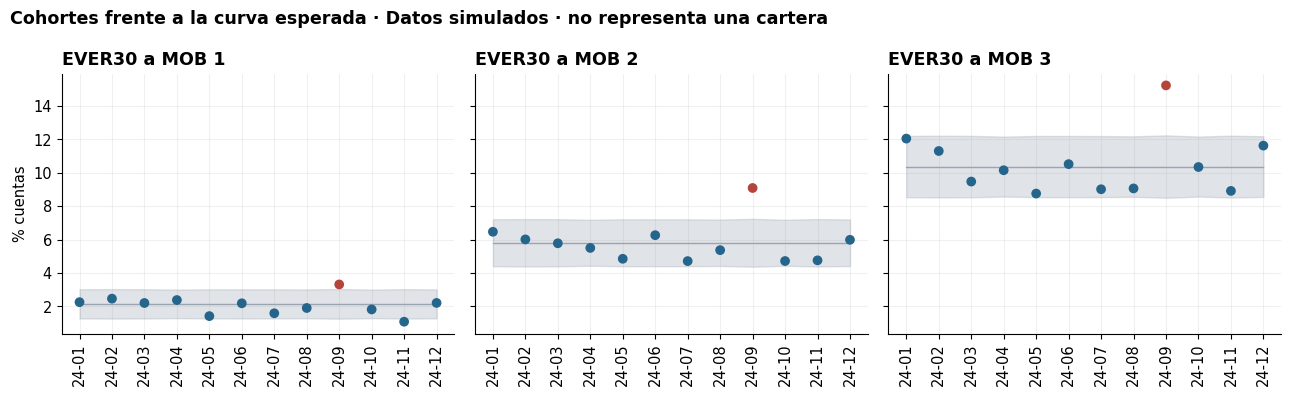

In [8]:
acc_demo, _ = build_vintage(panel_demo)
fija = panel_demo.merge(acc_demo.loc[acc_demo.es_evaluable, ['id_credito', 'id_comercio', 'corte_origen']])
curva = []
for h in (1, 2, 3):
    a_h, _ = build_vintage(fija, horizonte=h)
    curva.append(summarize_vintage(a_h).assign(mob=h))
curva = pd.concat(curva, ignore_index=True)
referencia = [f'2024-0{m}' for m in range(1, 7)]
bandas = dc.expected_curve_bands(curva, referencia)
print(f"Sobredispersión estimada φ = {bandas.attrs['sobredispersion']:.2f}")
alertas = bandas[(bandas.estado != 'en banda') & ~bandas.es_referencia]
display(alertas[['corte_origen', 'mob', 'n_maduros', 'tasa_observada', 'tasa_esperada', 'banda_alta', 'z', 'estado']])

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, m in zip(axs, (1, 2, 3)):
    b = bandas[bandas.mob == m].sort_values('corte_origen')
    ax.fill_between(range(len(b)), 100 * b.banda_baja, 100 * b.banda_alta, color=GRIS, alpha=.3, label='Banda esperada')
    ax.plot(range(len(b)), 100 * b.tasa_esperada, color=GRIS, lw=1)
    color = np.where(b.estado == 'sobre banda', ROJO, AZUL)
    ax.scatter(range(len(b)), 100 * b.tasa_observada, c=color, zorder=3)
    ax.set_xticks(range(len(b)), [c[2:] for c in b.corte_origen], rotation=90)
    ax.set_title(f'EVER30 a MOB {m}')
axs[0].set_ylabel('% cuentas'); fig.suptitle(f'Cohortes frente a la curva esperada · {SIM}', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### Demostración aislada: ¿cohorte o ciclo?

,efecto_log_odds,ic_bajo,ic_alto,relativo_mediana
cohorte,,,,
2024-02,-0.0457,-0.2490,0.1576,0.1278
2024-03,-0.1551,-0.3733,0.0631,0.0184
2024-04,-0.0273,-0.2494,0.1948,0.1461
2024-05,-0.2111,-0.4390,0.0168,-0.0376
2024-06,-0.0899,-0.2977,0.1179,0.0836
2024-07,-0.3133,-0.5274,-0.0992,-0.1399
2024-08,-0.2804,-0.4932,-0.0675,-0.1069
2024-09,0.3615,0.1643,0.5587,0.5349
2024-10,-0.1735,-0.3783,0.0314,0.0000


Efecto del desempleo: 0.226 log-odds por punto (IC 95 %: 0.102 a 0.350)


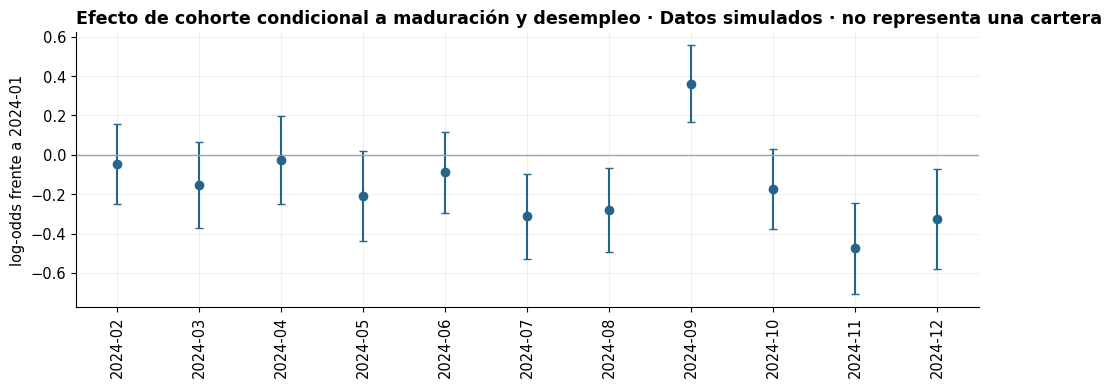

Prueba: se recupera la cohorte plantada y el IC del efecto macro contiene el valor plantado.


In [9]:
pp = dc.person_period(panel_demo)
pp['mes'] = (pd.PeriodIndex(pp.corte_origen, freq='M') + pp.mob).astype(str)
pp = pp.merge(macro_demo, on='mes', how='left', validate='many_to_one')
assert pp.desempleo.notna().all(), 'Falta la serie macro para algún mes'
efectos, ajuste = dc.fit_maturation_glm(pp, macro_cols=['desempleo'])
e = efectos.set_index('cohorte')
mediana = np.median(np.r_[0.0, e.efecto_log_odds.drop(V['efecto_cohorte_log_odds'].keys(), errors='ignore')])
e['relativo_mediana'] = e.efecto_log_odds - mediana
display(e[['efecto_log_odds', 'ic_bajo', 'ic_alto', 'relativo_mediana']])
b_macro, (lo_m, hi_m) = ajuste.params['desempleo'], ajuste.conf_int().loc['desempleo']
print(f'Efecto del desempleo: {b_macro:.3f} log-odds por punto (IC 95 %: {lo_m:.3f} a {hi_m:.3f})')

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(range(len(e)), e.efecto_log_odds, yerr=[e.efecto_log_odds - e.ic_bajo, e.ic_alto - e.efecto_log_odds],
            fmt='o', color=AZUL, capsize=3)
ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(range(len(e)), e.index, rotation=90)
ax.set(ylabel=f"log-odds frente a {efectos.attrs['referencia']}", title=f'Efecto de cohorte condicional a maduración y desempleo · {SIM}')
plt.tight_layout(); plt.show()

mala = list(V['efecto_cohorte_log_odds'])[0]
assert abs(e.loc[mala, 'relativo_mediana'] - V['efecto_cohorte_log_odds'][mala]) < .2
assert lo_m <= V['efecto_desempleo_log_odds'] <= hi_m
print('Prueba: se recupera la cohorte plantada y el IC del efecto macro contiene el valor plantado.')

In [10]:
filas = []
for c in sorted(alertas.corte_origen.unique()):
    estados = set(alertas.loc[alertas.corte_origen == c, 'estado'])
    rel = e.loc[c, 'relativo_mediana'] if c in e.index else np.nan
    if 'sobre banda' in estados:
        propia = c in e.index and e.loc[c, 'ic_bajo'] > 0 and rel > .2
        lectura = 'peor que lo esperado: calidad de originación' if propia else 'peor que lo esperado: ciclo / período'
    else:
        lectura = 'mejor que lo esperado: revisar política o mezcla de ese mes antes de atribuirlo'
    filas.append({'cohorte': c, 'MOB en alerta': ', '.join(map(str, alertas[alertas.corte_origen == c].mob)),
                  'efecto cohorte (rel.)': rel, 'lectura': lectura})
diagnostico = pd.DataFrame(filas); display(diagnostico)
texto = '; '.join(f"**{r.cohorte}**: {r.lectura}" for r in diagnostico.itertuples())
display(Markdown(f'**Lectura (simulada).** Cohortes fuera de banda: {texto}. La banda detecta la desviación; el hazard con '
                 'covariables macro indica si la desviación persiste tras descontar el entorno. Las cohortes desde 2024-07 '
                 'salen algo mejores porque la política de avance de TPV entra como calidad de cohorte: el notebook 10 la aísla.'))

,cohorte,MOB en alerta,efecto cohorte (rel.),lectura
0,2024-09,"1, 2, 3",0.5349,peor que lo esperado: calidad de originación
1,2024-11,1,-0.3022,mejor que lo esperado: revisar política o mezc...


**Lectura (simulada).** Cohortes fuera de banda: **2024-09**: peor que lo esperado: calidad de originación; **2024-11**: mejor que lo esperado: revisar política o mezcla de ese mes antes de atribuirlo. La banda detecta la desviación; el hazard con covariables macro indica si la desviación persiste tras descontar el entorno. Las cohortes desde 2024-07 salen algo mejores porque la política de avance de TPV entra como calidad de cohorte: el notebook 10 la aísla.

## Decisiones y límites

- **Para el comité:** reportar la pérdida esperada proyectada de cada cosecha joven con el rango que produce la inestabilidad del puente, y clasificar cada alerta como originación o entorno.
- **Acciones:** una cohorte con efecto propio significativo lleva a revisar la mezcla, los canales y la política vigente en ese mes. Una alerta explicada por el ciclo lleva a decisiones de cartera (cupos, cobranza), no a cambiar la originación.
- **Límites:** el puente asume cobranza y castigo estables; el efecto de cohorte depende de las covariables macro elegidas; la parte lineal del ciclo no es identificable. Las cuentas canceladas antes de MOB 18 requieren una regla explícita (riesgo competitivo).